In [1]:
import pandas as pd
import numpy as np
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Dense,Dropout,MaxPooling2D,Conv2D,Flatten

In [2]:
data=np.load("mnist.npz")

In [3]:
print(data.files)

['x_test', 'x_train', 'y_train', 'y_test']


In [4]:
X_train=data["x_train"]
X_test=data["x_test"]
y_train=data["y_train"]
y_test=data["y_test"]

In [5]:
X_train.shape


(60000, 28, 28)

In [6]:
y_train.shape

(60000,)

In [7]:
X_train=X_train/255
X_test=X_test/255

In [8]:
y_train_cat=to_categorical(y_train,10)
y_test_cat=to_categorical(y_test,10)

Text(0.5, 1.0, '5')

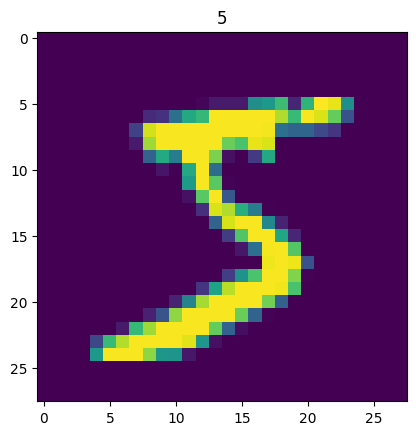

In [9]:
plt.imshow(X_train[0])
plt.title(y_train[0])

In [10]:
y_train_cat[0]

array([0., 0., 0., 0., 0., 1., 0., 0., 0., 0.])

In [11]:
dnn=Sequential([
    Input(shape=(28,28)),
    Flatten(),
    Dense(128,activation='relu'),
    Dropout(0.2),
    Dense(10,activation='softmax')
          
])

In [12]:
dnn.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
    

In [13]:
dnn.fit(X_train,y_train_cat,epochs=5,batch_size=128)

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8875 - loss: 0.3972
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9435 - loss: 0.1958
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9576 - loss: 0.1465
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9649 - loss: 0.1204
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9694 - loss: 0.1026


In [14]:
X_train_cnn=X_train.reshape(-1,28,28,1)
X_test_cnn=X_test.reshape(-1,28,28,1)


In [29]:
cnn=Sequential([
    Input(shape=(28,28,1)),
    Conv2D(32,(3,3),activation='relu'),
    
    MaxPooling2D(2,2),
   
    Flatten(),
    Dense(64,activation='relu'),
    Dense(10,activation='softmax')
])
          

In [30]:
cnn.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [31]:
cnn.fit(X_train_cnn,y_train_cat,epochs=5,batch_size=128)

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 14s 26ms/step - accuracy: 0.9260 - loss: 0.2600
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 20s 26ms/step - accuracy: 0.9759 - loss: 0.0819
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 21s 27ms/step - accuracy: 0.9832 - loss: 0.0568
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 21s 27ms/step - accuracy: 0.9874 - loss: 0.0436
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 21s 27ms/step - accuracy: 0.9900 - loss: 0.0344


In [34]:
dnn_loss,dnn_accuracy=dnn.evaluate(X_test,y_test_cat)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9724 - loss: 0.0908


In [35]:
cnn_loss,cnn_accuaracy=cnn.evaluate(X_test_cnn,y_test_cat)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9825 - loss: 0.0530
